# 03 · Expected credit loss and stress testing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/climate-tech-energy-finance/solar-loan-credit-risk/notebooks/03_ecl_and_stress_testing.ipynb)

This notebook takes the open book on 31 Oct 2026 and asks two questions an investor or warehouse lender will ask: how much do we expect to lose, and how bad does it get if power prices fall or a recession hits?

ECL follows the IFRS 9 staging logic: stage 1 gets a 12-month loss, stage 2 (30+ days late, or PD more than doubled since origination) a lifetime loss, stage 3 (defaulted, workout still open) LGD times exposure.

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "climate-tech-energy-finance/solar-loan-credit-risk"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "solar_credit").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: solar-loan-credit-risk


In [2]:
from solar_credit.data_generator import load_loan_book
from solar_credit.features import build_model_data
from solar_credit.scorecard import Scorecard
from solar_credit.ecl import current_book, lgd_by_product, roll_to_default_pd, compute_ecl
from solar_credit.stress import run_stress_tests, sensitivity_analysis
from solar_credit import config, reporting

book = load_loan_book()
md = build_model_data(book.loans)
sc = Scorecard().fit(md.X_train, md.y_train)
live = current_book(book.loans, book.performance)
print(f"Open loans incl. open workouts: {len(live):,}, exposure EUR {live['outstanding_balance_eur'].sum()/1e6:,.1f}m")

Open loans incl. open workouts: 8,834, exposure EUR 161.3m


## Inputs: LGD and roll-to-default

LGD comes from closed workouts, blended with a product prior through a credibility weight (n / (n + 30)). Heat pumps have the worst recoveries: once installed they are hard to take back and resell.

In [3]:
lgd = lgd_by_product(book.loans)
rolls = roll_to_default_pd(book.performance)
print("12m roll-to-default from 30 DPD: {:.1%}, from 60 DPD: {:.1%}".format(rolls[30], rolls[60]))
lgd

12m roll-to-default from 30 DPD: 68.3%, from 60 DPD: 89.8%


,product_type,prior_lgd,closed_workouts,realised_lgd,lgd
0,PV,0.62,109,0.617636,0.6181
1,PV+Battery,0.58,101,0.563641,0.5674
2,HeatPump,0.70,114,0.683742,0.6871
3,PV+Battery+Wallbox,0.55,34,0.521052,0.5346


In [4]:
pd_now = sc.predict_pd(live)
ecl = compute_ecl(live, pd_now, pd_now, lgd, rolls)
print(f"Total ECL EUR {ecl.total_ecl/1e6:,.2f}m, coverage {ecl.coverage:.2%}")
ecl.by_stage

Total ECL EUR 6.43m, coverage 3.99%


,stage,loans,exposure_eur,ecl_eur,coverage
0,1,8468,154290830.0,2161950.0,0.0140
1,2,52,872292.0,537195.0,0.6158
2,3,314,6094761.0,3735001.0,0.6128


Most of the provision sits in stage 3: 314 defaulted loans whose recoveries are still being worked out. Stage 1 loans need about 1.4% coverage.

## Scenarios

Shocks reach the PD through the model itself. Lower power prices shrink PV savings, which lowers the savings coverage ratio, which the scorecard re-scores. Unemployment is an overlay on the log-odds (+0.12 per percentage point), an expert assumption, because regional unemployment barely moved in the training data.

In [5]:
pd.DataFrame([vars(s) for s in config.SCENARIOS])

,name,electricity_price_change,unemployment_shift_pp,bureau_score_shift,lgd_add_on,description
0,Baseline,0.00,0.0,0.0,0.00,"Current assumptions, no shock."
1,Mild downturn,-0.15,1.0,-15.0,0.05,"Power prices fall 15%, unemployment +1pp, smal..."
2,Severe recession,-0.30,3.0,-40.0,0.12,"Power prices fall 30%, unemployment +3pp, inst..."
3,Installer default wave,0.00,0.0,0.0,0.20,"Several large installers fail: no PD change, r..."


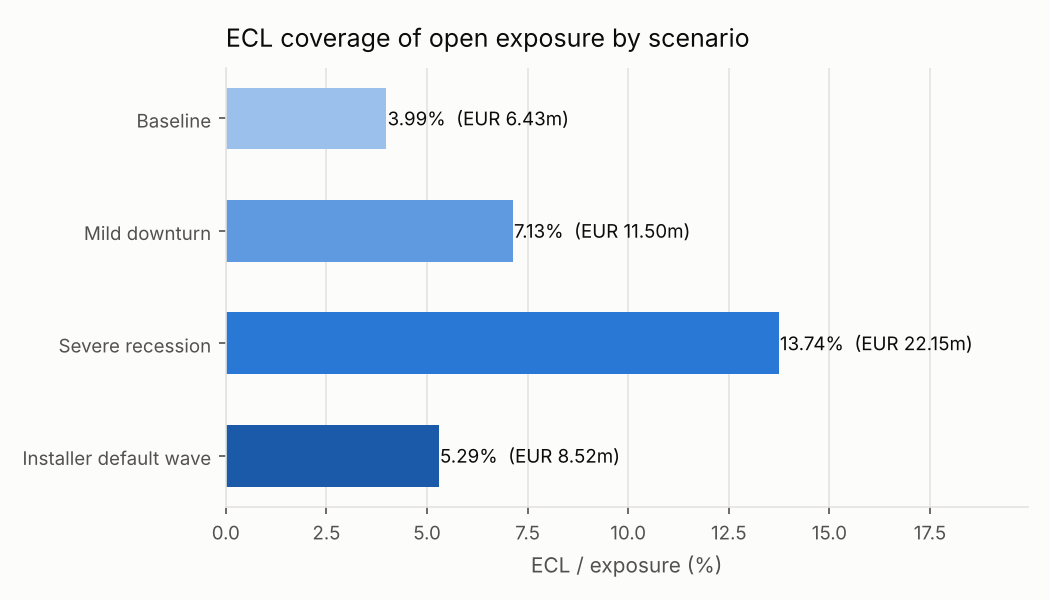

,scenario,avg_pd_12m,stage2_share_of_exposure,exposure_eur,ecl_eur,ecl_coverage,ecl_vs_baseline
0,Baseline,0.0284,0.0054,161257883.0,6434146.0,0.0399,1.000
1,Mild downturn,0.0403,0.3052,161257883.0,11502955.0,0.0713,1.788
2,Severe recession,0.0639,0.6270,161257883.0,22148916.0,0.1374,3.442
3,Installer default wave,0.0284,0.0054,161257883.0,8523969.0,0.0529,1.325


In [6]:
stress = run_stress_tests(live, sc.predict_pd, lgd, rolls)
display(Image(filename=str(reporting.plot_stress(stress, Path("outputs/figures/stress_scenarios.png")))))
stress.drop(columns="description")

The severe recession costs about 3.4 times the baseline ECL. Most of the jump is not higher 12-month PDs: it is loans crossing the stage 2 line, where a 12-month loss becomes a lifetime loss on 10 to 20 year terms. Investors should see this cliff effect before it happens, not after.

## Sensitivity: one driver at a time

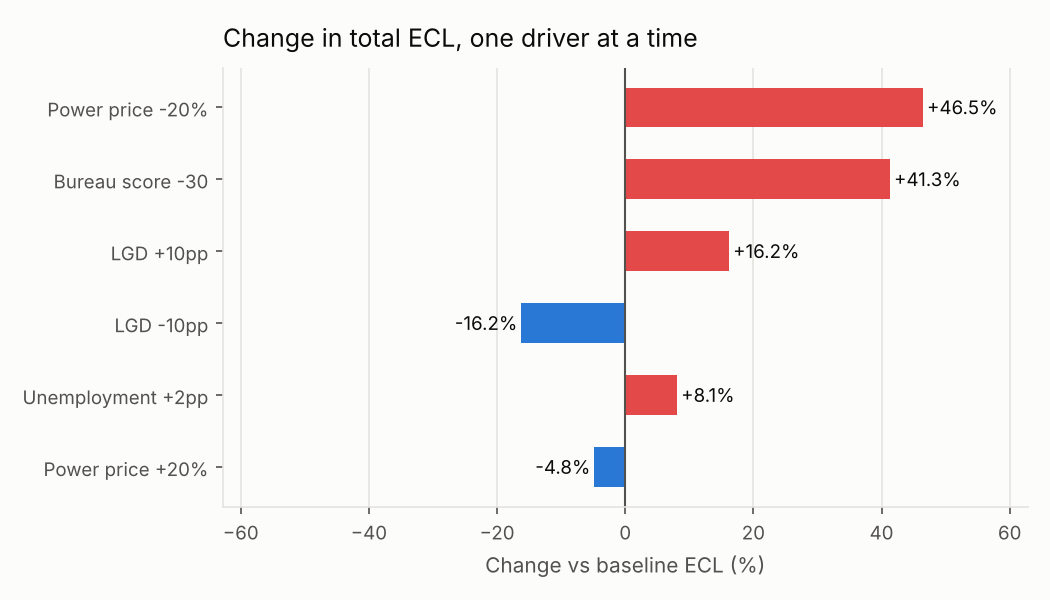

,shock,ecl_eur,change_eur,change_pct
0,Power price -20%,9425711.0,2991566.0,0.4650
1,Bureau score -30,9094967.0,2660821.0,0.4135
2,LGD +10pp,7479058.0,1044912.0,0.1624
3,LGD -10pp,5389235.0,-1044911.0,-0.1624
4,Unemployment +2pp,6957368.0,523222.0,0.0813
5,Power price +20%,6122654.0,-311492.0,-0.0484


In [7]:
sens = sensitivity_analysis(live, sc.predict_pd, lgd, rolls)
display(Image(filename=str(reporting.plot_sensitivity(sens, Path("outputs/figures/sensitivity_tornado.png")))))
sens

A 20% drop in power prices moves ECL more than a 30-point fall in every borrower's bureau score. For a green-energy lender, the electricity price is a credit risk factor, not just a sales argument. Two follow-ups would make sense: a covenant or pricing trigger tied to the savings coverage ratio, and monitoring of the forward power curve next to the delinquency report.

## Investor report

The full pipeline writes the report to `outputs/investor_report.md`.

In [8]:
from solar_credit.pipeline import run
summary = run()
print(open("outputs/investor_report.md").read()[:1500])

# Residential energy loan portfolio: investor report

As of 2026-10-31. Synthetic data, built to show the reporting workflow.

## Portfolio at a glance

| Metric | Value |
|---|---|
| Open loans | 8,520 |
| Open exposure | EUR 155.16m |
| 30+ DPD share of balance | 0.56% |
| Loans in open workout (defaulted) | 314 |
| Lifetime defaults to date | 672 (6.72% of loans written) |
| Largest installer share of book | 16.3% |
| Installer HHI | 521 |

## Expected credit loss (IFRS 9 style, baseline)

| stage | loans | exposure_eur | ecl_eur | coverage |
|---|---|---|---|---|
| 1 | 8468 | EUR 154.29m | EUR 2.16m | 1.40% |
| 2 | 52 | EUR 872,292 | EUR 537,195 | 61.58% |
| 3 | 314 | EUR 6.09m | EUR 3.74m | 61.28% |

Total ECL is EUR 6.43m, or 3.99% of exposure.

## Stress tests

| scenario | avg_pd_12m | stage2_share_of_exposure | ecl_eur | ecl_coverage | ecl_vs_baseline |
|---|---|---|---|---|---|
| Baseline | 2.84% | 0.5% | EUR 6.43m | 3.99% | 1.00x |
| Mild downturn | 4.03% | 30.5% | EUR 11.50